In [1]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/PathSnap_ip/PathSnap_shared6.zip"
data_dir = "/content/pathsnap_shared6"

if not os.path.isfile(zip_path):
    raise FileNotFoundError(
        "ZIP not found. Right-click it in Colab's Files panel, "
        "copy its path and update zip_path."
    )

os.makedirs(data_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(data_dir)

print("Extraction completed.")
print("Files:", sorted(os.listdir(data_dir)))

Extraction completed.
Files: ['cache_manifest.json', 'dataset_inventory.csv', 'feature_schema.json', 'final_scaler.joblib', 'fold_1_indices.npz', 'fold_1_scaler.joblib', 'fold_2_indices.npz', 'fold_2_scaler.joblib', 'fold_3_indices.npz', 'fold_3_scaler.joblib', 'fold_4_indices.npz', 'fold_4_scaler.joblib', 'fold_5_indices.npz', 'fold_5_scaler.joblib', 'fold_assignments.csv', 'pathsnap_shared6.py', 'shared_inputs.npz', 'shared_protocol.json', 'student_test_candidates.csv.gz', 'student_test_features.npz', 'student_test_inventory.csv', 'student_test_observations.csv.gz', 'train_candidates.csv.gz', 'train_features.npz', 'train_inventory.csv', 'train_observations.csv.gz']


In [3]:
import json
import numpy as np
import pandas as pd

with np.load(
    os.path.join(data_dir, "shared_inputs.npz"),
    allow_pickle=False
) as shared:

    # Use RAW features: the MLP pipeline will fit its own scaler
    # on the appropriate training data.
    X_train = shared["X_train_raw"].copy()
    y_train = shared["y_train"].copy()

    X_test = shared["X_test_raw"].copy()
    y_test = shared["y_test"].copy()

    feature_names = shared["features"].tolist()

    train_trip_id = shared["train_trip_id"].copy()
    test_trip_id = shared["test_trip_id"].copy()

    train_observation_id = shared["train_observation_id"].copy()
    test_observation_id = shared["test_observation_id"].copy()

    train_arc_id = shared["train_arc_id"].copy()
    test_arc_id = shared["test_arc_id"].copy()

    fold_id = shared["fold_id"].copy()

# Observation files include points even when no candidate was generated.
train_observations = pd.read_csv(
    os.path.join(data_dir, "train_observations.csv.gz"),
    dtype={"trip_id": str}
)

test_observations = pd.read_csv(
    os.path.join(data_dir, "student_test_observations.csv.gz"),
    dtype={"trip_id": str}
)

print("Features:", feature_names)
print("Training candidates:", X_train.shape)
print("Student-test candidates:", X_test.shape)
print("Training trips:", len(np.unique(train_trip_id)))
print("Student-test trips:", len(np.unique(test_trip_id)))
print("Training observations:", len(train_observations))
print("Student-test observations:", len(test_observations))

print("\nTraining label counts:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nStudent-test label counts:")
print(pd.Series(y_test).value_counts().sort_index())

print("\nNon-finite training feature values:", (~np.isfinite(X_train)).sum())
print("Non-finite test feature values:", (~np.isfinite(X_test)).sum())

assert X_train.shape[1] == len(feature_names) == 6
assert len(X_train) == len(y_train) == len(fold_id)
assert len(X_test) == len(y_test)
assert len(np.unique(train_trip_id)) == 80
assert len(np.unique(test_trip_id)) == 10
assert not set(train_trip_id).intersection(set(test_trip_id))
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
assert set(np.unique(fold_id)) == {1, 2, 3, 4, 5}

# Verify that no trip appears in multiple validation folds.
trip_fold_check = pd.DataFrame({
    "trip_id": train_trip_id,
    "fold": fold_id
}).groupby("trip_id")["fold"].nunique()

assert (trip_fold_check == 1).all(), "A trip appears in multiple folds."

print("\nData checks passed.")

Features: ['distance_m', 'distance_rank', 'heading_difference_deg', 'projection_fraction', 'segment_length_m', 'displacement_m']
Training candidates: (1241756, 6)
Student-test candidates: (125525, 6)
Training trips: 80
Student-test trips: 10
Training observations: 208417
Student-test observations: 19160

Training label counts:
0    1056407
1     185349
Name: count, dtype: int64

Student-test label counts:
0    106413
1     19112
Name: count, dtype: int64

Non-finite training feature values: 0
Non-finite test feature values: 0

Data checks passed.


In [4]:
import time

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    confusion_matrix
)

RANDOM_SEED = 42


def create_mlp():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            max_iter=50,
            early_stopping=False,
            random_state=RANDOM_SEED
        ))
    ])


def evaluate_model(
    model, X, y, trip_ids, observation_ids, arc_ids, observations
):
    # Measure model scoring time on prepared candidate rows.
    start = time.perf_counter()
    probabilities = model.predict_proba(X)[:, 1]
    inference_seconds = time.perf_counter() - start

    # Candidate-level predictions use a 0.5 threshold.
    predictions = (probabilities >= 0.5).astype(int)

    candidates = pd.DataFrame({
        "trip_id": trip_ids.astype(str),
        "observation_id": observation_ids,
        "arc_id": arc_ids,
        "label": y,
        "score": probabilities
    })

    # Deterministic tie handling: lower arc ID appears first.
    candidates = candidates.sort_values(
        ["trip_id", "observation_id", "arc_id"]
    ).reset_index(drop=True)

    best_indices = candidates.groupby(
        ["trip_id", "observation_id"], sort=False
    )["score"].idxmax()

    best_candidates = candidates.loc[best_indices]

    # Observation file includes observations with no candidates.
    total_observations = len(observations)

    if total_observations == 0:
        raise ValueError("No observations found for this evaluation.")

    correct_top1 = int(best_candidates["label"].sum())

    # reference_present comes from the shared preprocessing.
    reference_present = observations["reference_present"]
    if reference_present.dtype != bool:
        reference_present = (
            reference_present.astype(str).str.lower().map({
                "true": True,
                "false": False
            })
        )

    if reference_present.isna().any():
        raise ValueError("Could not interpret reference_present values.")

    candidate_misses = int((~reference_present).sum())

    results = {
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Recall": recall_score(y, predictions, zero_division=0),
        "Positive F1": f1_score(y, predictions, zero_division=0),
        "Macro F1": f1_score(
            y, predictions, average="macro", zero_division=0
        ),
        "Log loss": log_loss(y, probabilities, labels=[0, 1]),
        "Top-1 accuracy": correct_top1 / total_observations,
        "Approx. miss rate": candidate_misses / total_observations,
        "Inference seconds": inference_seconds
    }

    matrix = confusion_matrix(y, predictions, labels=[0, 1])

    return results, matrix


print("MLP and evaluation functions are ready.")

MLP and evaluation functions are ready.


In [5]:
final_mlp = create_mlp()

print("Training final MLP on all 80 training trips...")
start = time.perf_counter()

final_mlp.fit(X_train, y_train)

final_training_seconds = time.perf_counter() - start
print(f"Training completed in {final_training_seconds:.2f} seconds")

student_results, student_matrix = evaluate_model(
    model=final_mlp,
    X=X_test,
    y=y_test,
    trip_ids=test_trip_id,
    observation_ids=test_observation_id,
    arc_ids=test_arc_id,
    observations=test_observations
)

print("\n========== STUDENT-TEST RESULTS ==========")

for metric, value in student_results.items():
    print(f"{metric}: {value:.4f}")

print(f"Training seconds: {final_training_seconds:.2f}")

print("\nConfusion matrix:")
print("Rows: approximate actual labels [0, 1]")
print("Columns: predicted labels [0, 1]")
print(student_matrix)

Training final MLP on all 80 training trips...
Training completed in 125.27 seconds

========== STUDENT-TEST RESULTS ==========
Accuracy: 0.9429
Precision: 0.8378
Recall: 0.7753
Positive F1: 0.8054
Macro F1: 0.8860
Log loss: 0.1388
Top-1 accuracy: 0.8259
Approx. miss rate: 0.0025
Inference seconds: 0.0398
Training seconds: 125.27

Confusion matrix:
Rows: approximate actual labels [0, 1]
Columns: predicted labels [0, 1]
[[103545   2868]
 [  4294  14818]]


In [6]:
cv_results = []
cv_matrices = {}

for fold in [1, 2, 3, 4, 5]:
    train_mask = fold_id != fold
    val_mask = fold_id == fold

    validation_trips = np.unique(train_trip_id[val_mask])

    fold_observations = train_observations[
        train_observations["trip_id"].isin(validation_trips)
    ]

    print(f"\nTraining fold {fold}/5...")
    print("Training trips:", len(np.unique(train_trip_id[train_mask])))
    print("Validation trips:", len(validation_trips))

    model = create_mlp()

    start = time.perf_counter()
    model.fit(X_train[train_mask], y_train[train_mask])
    training_seconds = time.perf_counter() - start

    results, matrix = evaluate_model(
        model=model,
        X=X_train[val_mask],
        y=y_train[val_mask],
        trip_ids=train_trip_id[val_mask],
        observation_ids=train_observation_id[val_mask],
        arc_ids=train_arc_id[val_mask],
        observations=fold_observations
    )

    results["Fold"] = fold
    results["Training seconds"] = training_seconds

    cv_results.append(results)
    cv_matrices[fold] = matrix

    print(f"Training time: {training_seconds:.2f} seconds")
    print(f"Candidate accuracy: {results['Accuracy']:.4f}")
    print(f"Macro F1: {results['Macro F1']:.4f}")
    print(f"Top-1 accuracy: {results['Top-1 accuracy']:.4f}")
    print("Confusion matrix:\n", matrix)

cv_results_df = pd.DataFrame(cv_results)

print("\n========== FIVE-FOLD RESULTS ==========")
print(cv_results_df.round(4).to_string(index=False))

print("\n========== MEAN RESULTS ==========")
print(cv_results_df.drop(columns="Fold").mean().round(4))


Training fold 1/5...
Training trips: 65
Validation trips: 15


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Training time: 141.17 seconds
Candidate accuracy: 0.9281
Macro F1: 0.8389
Top-1 accuracy: 0.4513
Confusion matrix:
 [[159503   6795]
 [  6919  17554]]

Training fold 2/5...
Training trips: 64
Validation trips: 16


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Training time: 121.66 seconds
Candidate accuracy: 0.9248
Macro F1: 0.8516
Top-1 accuracy: 0.7602
Confusion matrix:
 [[214338   8074]
 [ 11739  29296]]

Training fold 3/5...
Training trips: 64
Validation trips: 16


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Training time: 124.00 seconds
Candidate accuracy: 0.9128
Macro F1: 0.8495
Top-1 accuracy: 0.7624
Confusion matrix:
 [[182027   9406]
 [ 10913  30781]]

Training fold 4/5...
Training trips: 64
Validation trips: 16


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Training time: 119.33 seconds
Candidate accuracy: 0.9537
Macro F1: 0.9003
Top-1 accuracy: 0.7847
Confusion matrix:
 [[235001   6522]
 [  6398  30962]]

Training fold 5/5...
Training trips: 63
Validation trips: 17


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Training time: 118.82 seconds
Candidate accuracy: 0.9374
Macro F1: 0.8721
Top-1 accuracy: 0.7828
Confusion matrix:
 [[227616   7125]
 [ 10114  30673]]

========== FIVE-FOLD RESULTS ==========
 Accuracy  Precision  Recall  Positive F1  Macro F1  Log loss  Top-1 accuracy  Approx. miss rate  Inference seconds  Fold  Training seconds
   0.9281     0.7209  0.7173       0.7191    0.8389    0.1678          0.4513             0.4138             0.0515     1          141.1685
   0.9248     0.7839  0.7139       0.7473    0.8516    0.1864          0.7602             0.0169             0.0699     2          121.6646
   0.9128     0.7659  0.7383       0.7518    0.8495    0.1919          0.7624             0.0010             0.0622     3          123.9992
   0.9537     0.8260  0.8287       0.8274    0.9003    0.1168          0.7847             0.0980             0.0748     4          119.3285
   0.9374     0.8115  0.7520       0.7806    0.8721    0.1520          0.7828             0.0237            

In [7]:
%pip -q install matplotlib folium

In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium

from IPython.display import display
from sklearn.metrics import log_loss

# Save the generated figures and map in Drive
OUTPUT_DIR = "/content/drive/MyDrive/PathSnap_MLP_shared_results/plots"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Output folder:", OUTPUT_DIR)

Output folder: /content/drive/MyDrive/PathSnap_MLP_shared_results/plots


In [9]:
student_results_df = pd.DataFrame([student_results])

print("STUDENT-TEST RESULTS")
display(student_results_df)

print("\nFinal model training time:")
print(f"{final_training_seconds:.2f} seconds")

STUDENT-TEST RESULTS


,Accuracy,Precision,Recall,Positive F1,Macro F1,Log loss,Top-1 accuracy,Approx. miss rate,Inference seconds
0,0.942944,0.837838,0.775324,0.80537,0.885971,0.138775,0.825887,0.002505,0.039803



Final model training time:
125.27 seconds


CV MACRO F1


,Fold,Macro F1
0,1,0.838942
1,2,0.851561
2,3,0.849492
3,4,0.900310
4,5,0.872073



Average and standard deviation:


,Macro F1
mean,0.862476
std,0.024316


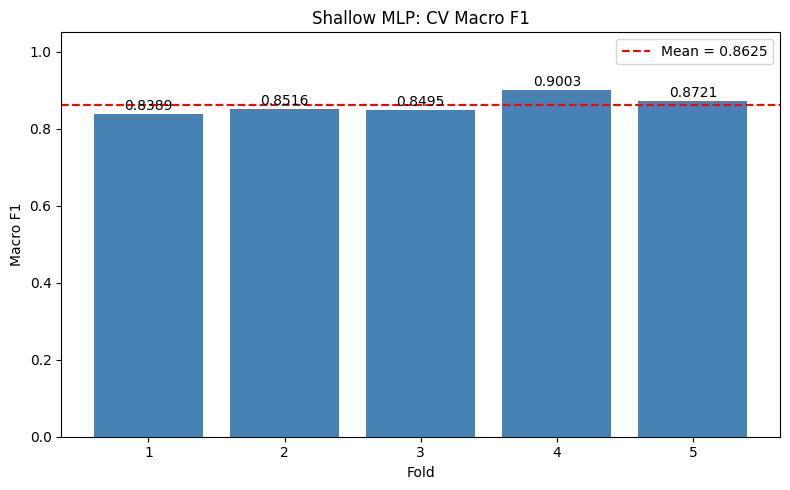

In [10]:
cv_macro = cv_results_df[["Fold", "Macro F1"]].copy()

print("CV MACRO F1")
display(cv_macro)

print("\nAverage and standard deviation:")
display(cv_macro[["Macro F1"]].agg(["mean", "std"]))

# Plot the five fold scores
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    cv_macro["Fold"].astype(str),
    cv_macro["Macro F1"],
    color="steelblue"
)

mean_macro_f1 = cv_macro["Macro F1"].mean()

ax.axhline(
    mean_macro_f1,
    color="red",
    linestyle="--",
    label=f"Mean = {mean_macro_f1:.4f}"
)

for index, score in enumerate(cv_macro["Macro F1"]):
    ax.text(
        index,
        score + 0.01,
        f"{score:.4f}",
        ha="center"
    )

ax.set_title("Shallow MLP: CV Macro F1")
ax.set_xlabel("Fold")
ax.set_ylabel("Macro F1")
ax.set_ylim(0, 1.05)
ax.legend()

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "mlp_cv_macro_f1.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

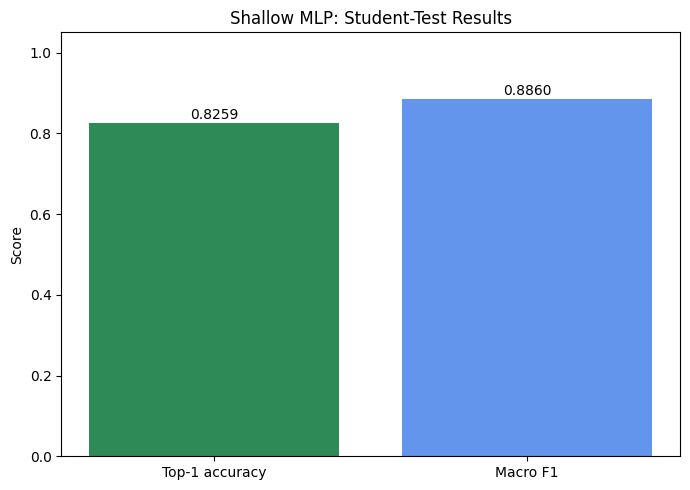

In [11]:
metric_names = ["Top-1 accuracy", "Macro F1"]

metric_values = [
    student_results["Top-1 accuracy"],
    student_results["Macro F1"]
]

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    metric_names,
    metric_values,
    color=["seagreen", "cornflowerblue"]
)

for bar, value in zip(bars, metric_values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.4f}",
        ha="center"
    )

ax.set_title("Shallow MLP: Student-Test Results")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "mlp_student_top1_macro_f1.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

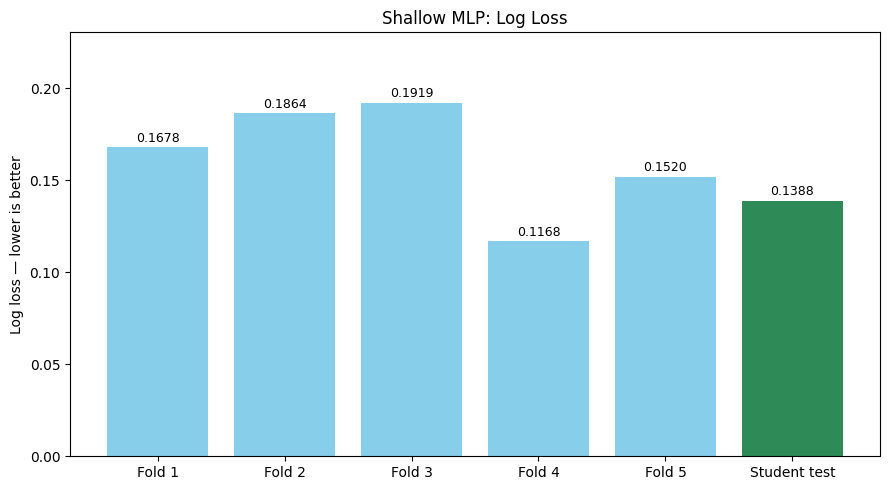

In [12]:
fold_labels = [
    f"Fold {int(fold)}"
    for fold in cv_results_df["Fold"]
]

log_losses = cv_results_df["Log loss"].tolist()

fold_labels.append("Student test")
log_losses.append(student_results["Log loss"])

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    fold_labels,
    log_losses,
    color=["skyblue"] * 5 + ["seagreen"]
)

for bar, value in zip(bars, log_losses):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.003,
        f"{value:.4f}",
        ha="center",
        fontsize=9
    )

ax.set_title("Shallow MLP: Log Loss")
ax.set_ylabel("Log loss — lower is better")
ax.set_ylim(0, max(log_losses) * 1.2)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "mlp_log_loss.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

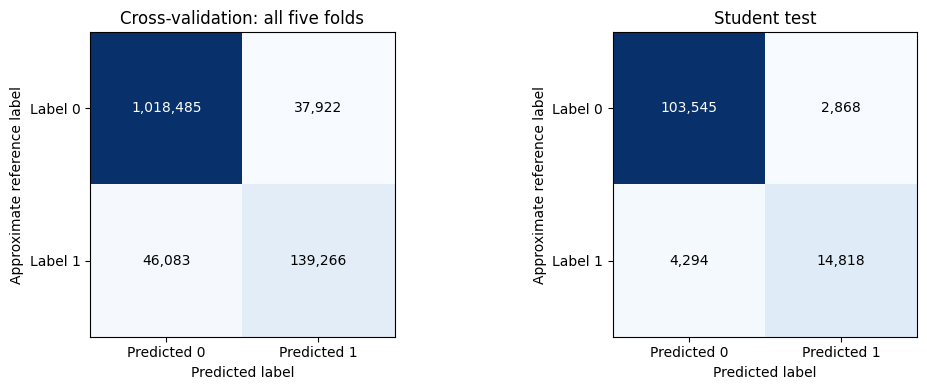

In [13]:
# Sum the five validation-fold confusion matrices
cv_matrix = sum(
    (cv_matrices[fold] for fold in range(1, 6)),
    start=np.zeros((2, 2), dtype=int)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, matrix, title in zip(
    axes,
    [cv_matrix, student_matrix],
    ["Cross-validation: all five folds", "Student test"]
):
    ax.imshow(matrix, cmap="Blues")

    for row in range(2):
        for col in range(2):
            ax.text(
                col,
                row,
                f"{matrix[row, col]:,}",
                ha="center",
                va="center",
                color=(
                    "white"
                    if matrix[row, col] > matrix.max() / 2
                    else "black"
                )
            )

    ax.set_xticks([0, 1], ["Predicted 0", "Predicted 1"])
    ax.set_yticks([0, 1], ["Label 0", "Label 1"])
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Approximate reference label")
    ax.set_title(title)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "mlp_confusion_matrices.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

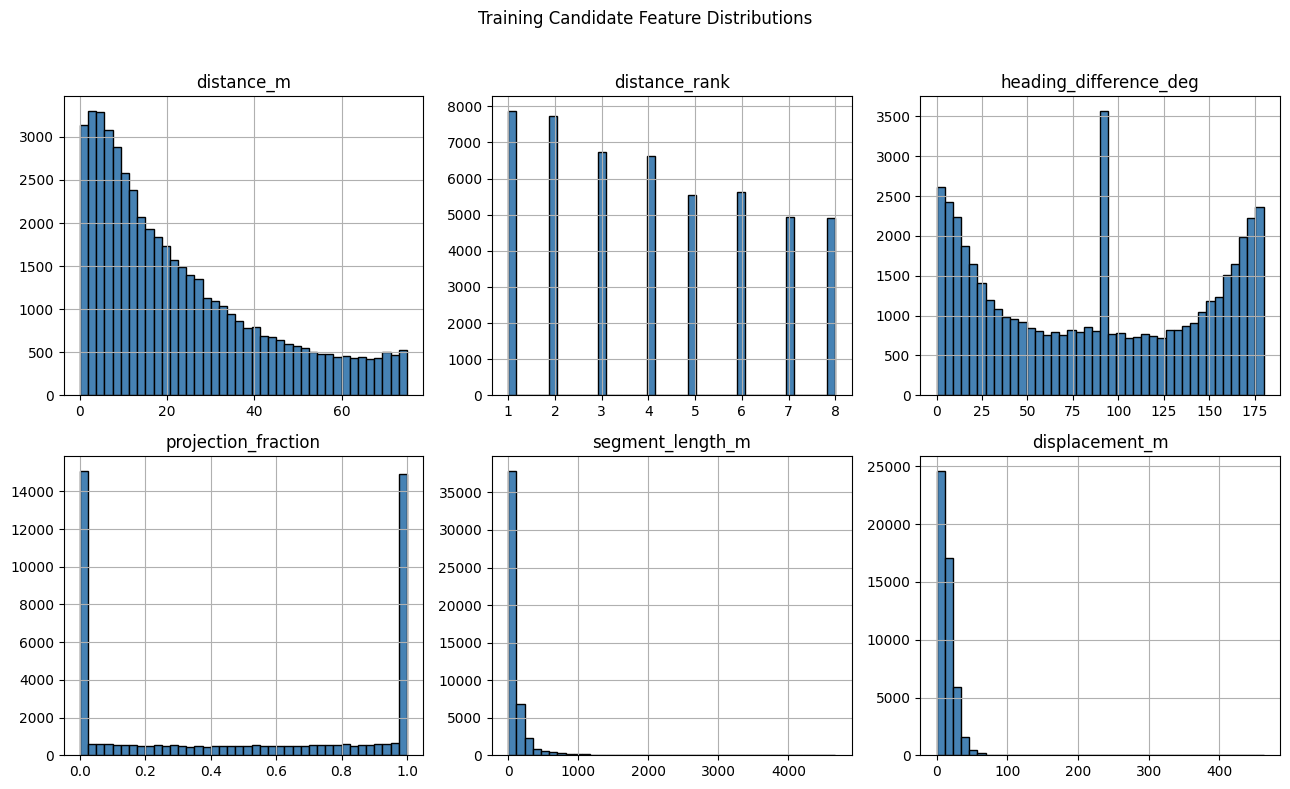

Training candidate rows sampled: 50000


In [14]:
rng = np.random.default_rng(42)

sample_size = min(50_000, len(X_train))

sample_indices = rng.choice(
    len(X_train),
    size=sample_size,
    replace=False
)

train_sample = pd.DataFrame(
    X_train[sample_indices],
    columns=feature_names
)

train_sample.hist(
    bins=40,
    figsize=(13, 8),
    layout=(2, 3),
    color="steelblue",
    edgecolor="black"
)

plt.suptitle("Training Candidate Feature Distributions")
plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    os.path.join(OUTPUT_DIR, "mlp_feature_distributions.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Training candidate rows sampled:", sample_size)

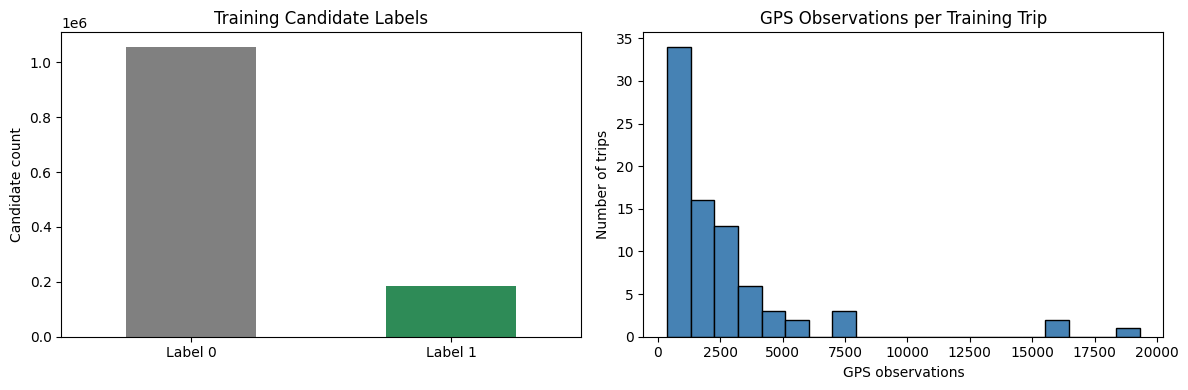

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Candidate label distribution
label_counts = pd.Series(y_train).value_counts().reindex(
    [0, 1],
    fill_value=0
)

label_counts.plot.bar(
    ax=axes[0],
    color=["gray", "seagreen"]
)

axes[0].set_title("Training Candidate Labels")
axes[0].set_xticklabels(
    ["Label 0", "Label 1"],
    rotation=0
)
axes[0].set_ylabel("Candidate count")

# GPS observations per trip
train_observations.groupby("trip_id").size().plot.hist(
    bins=20,
    ax=axes[1],
    color="steelblue",
    edgecolor="black"
)

axes[1].set_title("GPS Observations per Training Trip")
axes[1].set_xlabel("GPS observations")
axes[1].set_ylabel("Number of trips")

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "mlp_training_eda.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss

loss_histories = []

# To keep memory and computation manageable, each epoch's
# training loss is measured on the same fixed training sample.
MAX_TRAIN_LOSS_ROWS = 100_000
EPOCHS = 50

for fold in range(1, 6):
    print(f"\nRecording loss curves for fold {fold}/5...")

    fit_mask = fold_id != fold
    valid_mask = fold_id == fold

    X_fit_raw = X_train[fit_mask]
    y_fit = y_train[fit_mask]

    X_valid_raw = X_train[valid_mask]
    y_valid = y_train[valid_mask]

    # Fit scaling only on this fold's training rows.
    scaler = StandardScaler()

    X_fit_scaled = scaler.fit_transform(X_fit_raw)
    X_valid_scaled = scaler.transform(X_valid_raw)

    estimator = MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=1,
        random_state=42
    )

    # Fixed sample used only to measure training log loss.
    rng = np.random.default_rng(42)
    sample_size = min(MAX_TRAIN_LOSS_ROWS, len(X_fit_scaled))

    train_loss_indices = rng.choice(
        len(X_fit_scaled),
        size=sample_size,
        replace=False
    )

    X_train_loss = X_fit_scaled[train_loss_indices]
    y_train_loss = y_fit[train_loss_indices]

    history = {
        "fold": fold,
        "training_log_loss": [],
        "validation_log_loss": []
    }

    for epoch in range(EPOCHS):
        # partial_fit performs one incremental pass.
        if epoch == 0:
            estimator.partial_fit(
                X_fit_scaled,
                y_fit,
                classes=np.array([0, 1])
            )
        else:
            estimator.partial_fit(
                X_fit_scaled,
                y_fit
            )

        train_prob = estimator.predict_proba(X_train_loss)[:, 1]
        valid_prob = estimator.predict_proba(X_valid_scaled)[:, 1]

        train_loss = log_loss(
            y_train_loss,
            train_prob,
            labels=[0, 1]
        )

        valid_loss = log_loss(
            y_valid,
            valid_prob,
            labels=[0, 1]
        )

        history["training_log_loss"].append(train_loss)
        history["validation_log_loss"].append(valid_loss)

        if (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch + 1:02d} | "
                f"Train loss: {train_loss:.4f} | "
                f"Validation loss: {valid_loss:.4f}"
            )

    loss_histories.append(history)

    # Release large fold arrays before the next fold.
    del X_fit_raw, X_valid_raw
    del X_fit_scaled, X_valid_scaled


Recording loss curves for fold 1/5...
Epoch 10 | Train loss: 0.1493 | Validation loss: 0.1604
Epoch 20 | Train loss: 0.1475 | Validation loss: 0.1592
Epoch 30 | Train loss: 0.1470 | Validation loss: 0.1583
Epoch 40 | Train loss: 0.1469 | Validation loss: 0.1590
Epoch 50 | Train loss: 0.1463 | Validation loss: 0.1582

Recording loss curves for fold 2/5...
Epoch 10 | Train loss: 0.1463 | Validation loss: 0.1756
Epoch 20 | Train loss: 0.1451 | Validation loss: 0.1762
Epoch 30 | Train loss: 0.1442 | Validation loss: 0.1767
Epoch 40 | Train loss: 0.1434 | Validation loss: 0.1764
Epoch 50 | Train loss: 0.1430 | Validation loss: 0.1766

Recording loss curves for fold 3/5...
Epoch 10 | Train loss: 0.1427 | Validation loss: 0.1901
Epoch 20 | Train loss: 0.1412 | Validation loss: 0.1903
Epoch 30 | Train loss: 0.1407 | Validation loss: 0.1909
Epoch 40 | Train loss: 0.1403 | Validation loss: 0.1918
Epoch 50 | Train loss: 0.1401 | Validation loss: 0.1921

Recording loss curves for fold 4/5...
Epoc

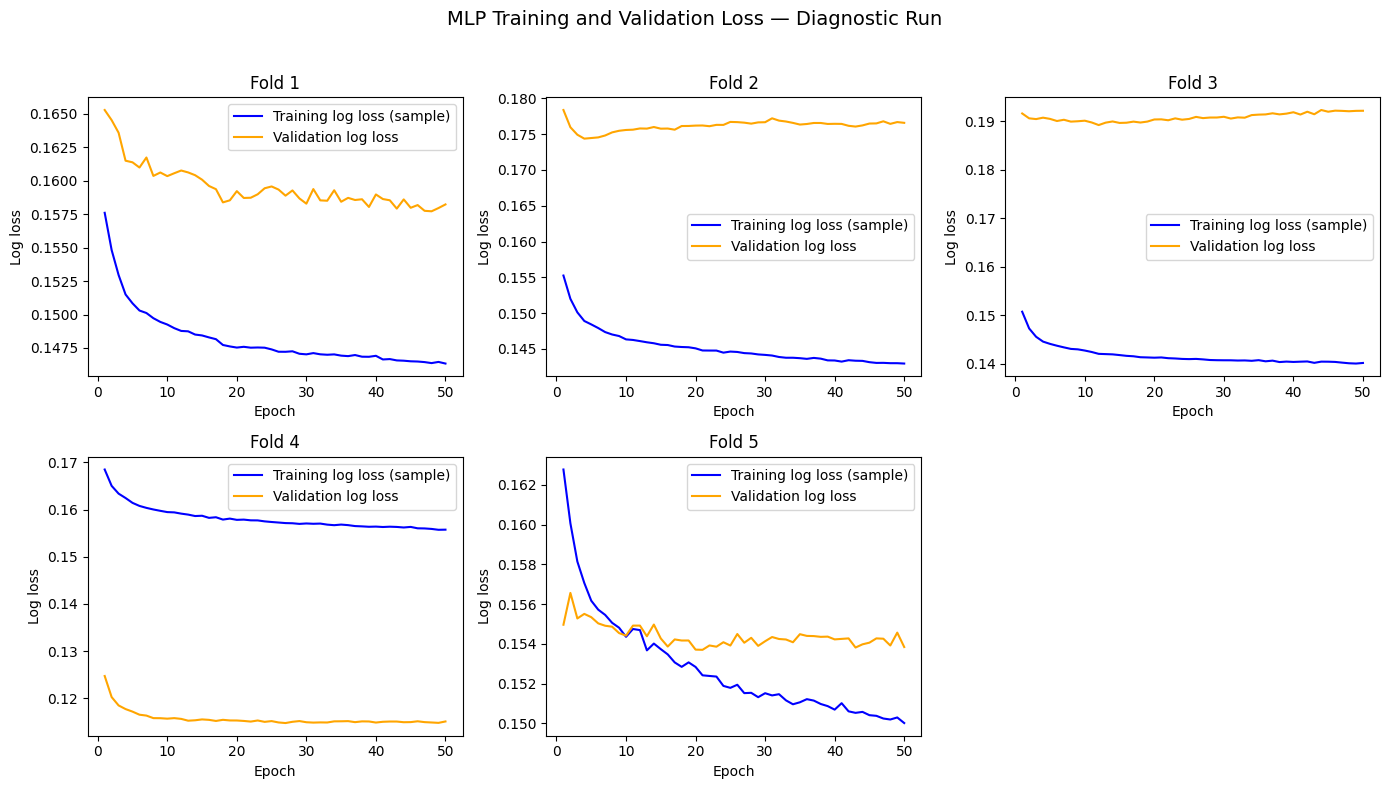

Plot saved to: /content/drive/MyDrive/PathSnap_MLP_shared_results/plots/mlp_training_validation_loss.png


In [17]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for index, history in enumerate(loss_histories):
    ax = axes.flat[index]

    epochs = range(1, len(history["training_log_loss"]) + 1)

    ax.plot(
        epochs,
        history["training_log_loss"],
        label="Training log loss (sample)",
        color="blue"
    )

    ax.plot(
        epochs,
        history["validation_log_loss"],
        label="Validation log loss",
        color="orange"
    )

    ax.set_title(f"Fold {history['fold']}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Log loss")
    ax.legend()

axes.flat[-1].axis("off")

plt.suptitle(
    "MLP Training and Validation Loss — Diagnostic Run",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plot_path = os.path.join(
    OUTPUT_DIR,
    "mlp_training_validation_loss.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Plot saved to:", plot_path)

In [18]:
loss_rows = []

for history in loss_histories:
    for epoch, (train_loss, valid_loss) in enumerate(
        zip(
            history["training_log_loss"],
            history["validation_log_loss"]
        ),
        start=1
    ):
        loss_rows.append({
            "fold": history["fold"],
            "epoch": epoch,
            "training_log_loss_sample": train_loss,
            "validation_log_loss": valid_loss
        })

loss_history_df = pd.DataFrame(loss_rows)

loss_path = os.path.join(OUTPUT_DIR, "mlp_loss_histories.csv")
loss_history_df.to_csv(loss_path, index=False)

print("Loss values saved to:", loss_path)

Loss values saved to: /content/drive/MyDrive/PathSnap_MLP_shared_results/plots/mlp_loss_histories.csv
